we are going to simulate the core principles behind Shor’s Algorithm using a small factoring problem. The goal is to understand how periodic behaviour, the Quantum Fourier Transform, and classical post-processing work together to recover the factors of a number.

In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram, plot_state_city

import numpy as np
import math

In [3]:
N = 15
a = 2

print(f"Number to factor: {N}")
print(f"Chosen base: {a}")

Number to factor: 15
Chosen base: 2


In [4]:
gcd_value = math.gcd(a, N)

print(f"gcd({a}, {N}) = {gcd_value}")

gcd(2, 15) = 1


In [5]:
x_values = list(range(8))

modular_values = [
    pow(a, x, N)
    for x in x_values
]

for x, value in zip(x_values, modular_values):
    print(f"2^{x} mod 15 = {value}")

2^0 mod 15 = 1
2^1 mod 15 = 2
2^2 mod 15 = 4
2^3 mod 15 = 8
2^4 mod 15 = 1
2^5 mod 15 = 2
2^6 mod 15 = 4
2^7 mod 15 = 8


In [6]:
num_qubits = 4
dimension = 2 ** num_qubits

amplitudes = np.zeros(
    dimension,
    dtype=complex
)

periodic_indices = [0, 4, 8, 12]

for index in periodic_indices:
    amplitudes[index] = 1 / 2

periodic_state = Statevector(amplitudes)

print(periodic_state)

Statevector([0.5+0.j, 0. +0.j, 0. +0.j, 0. +0.j, 0.5+0.j, 0. +0.j, 0. +0.j,
             0. +0.j, 0.5+0.j, 0. +0.j, 0. +0.j, 0. +0.j, 0.5+0.j, 0. +0.j,
             0. +0.j, 0. +0.j],
            dims=(2, 2, 2, 2))


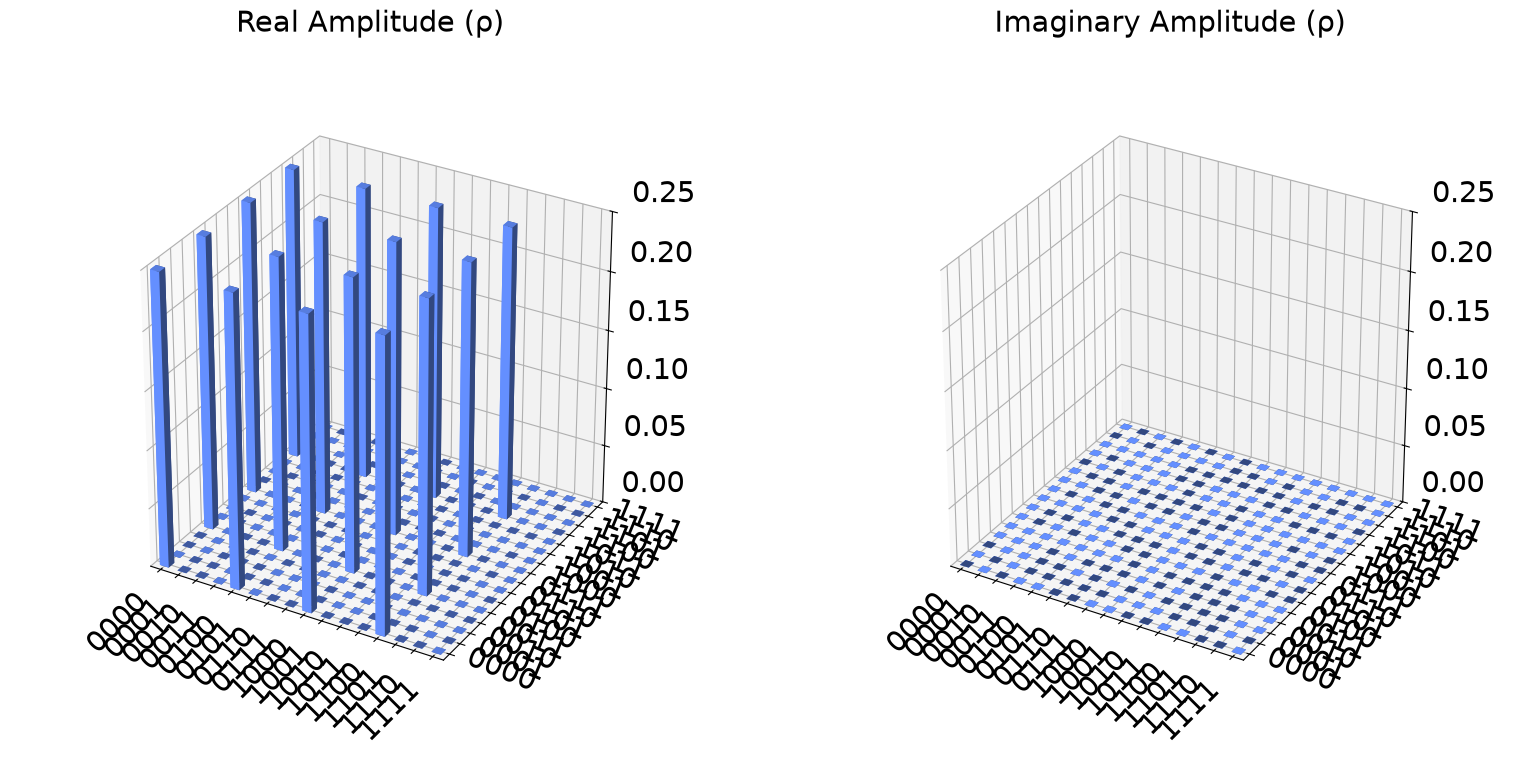

In [7]:
plot_state_city(periodic_state)

In [8]:
def qft_circuit(n):
    circuit = QuantumCircuit(n)

    for target in range(n):
        circuit.h(target)

        for control in range(target + 1, n):
            angle = np.pi / (2 ** (control - target))

            circuit.cp(
                angle,
                control,
                target
            )

    for qubit in range(n // 2):
        circuit.swap(
            qubit,
            n - qubit - 1
        )

    return circuit

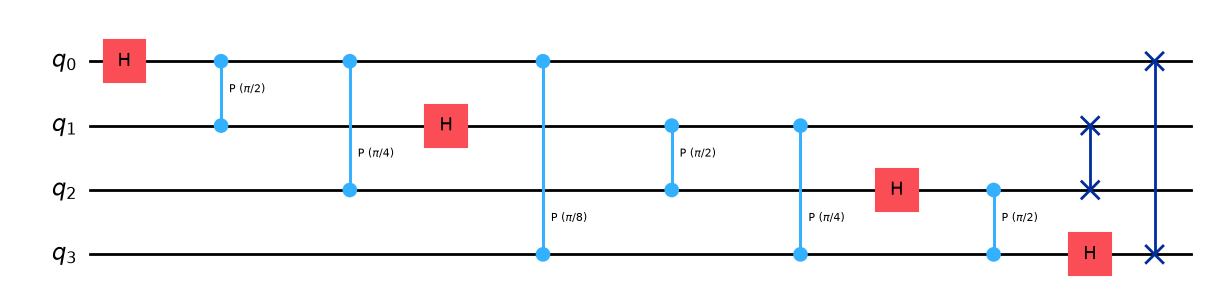

In [9]:
qft = qft_circuit(num_qubits)

qft.draw("mpl")

In [10]:
frequency_state = periodic_state.evolve(qft)

print(
    frequency_state.probabilities_dict()
)

{np.str_('0000'): np.float64(0.24999999999999983), np.str_('0001'): np.float64(9.682320048931735e-38), np.str_('0010'): np.float64(1.3217493523837122e-34), np.str_('0011'): np.float64(1.3217493523837122e-34), np.str_('0100'): np.float64(0.10669417382415919), np.str_('0101'): np.float64(0.018305826175840766), np.str_('0110'): np.float64(0.018305826175840773), np.str_('0111'): np.float64(0.10669417382415919), np.str_('1000'): np.float64(0.20526673725850128), np.str_('1001'): np.float64(0.008121610389817027), np.str_('1010'): np.float64(0.011300489782591317), np.str_('1011'): np.float64(0.025311162569090224), np.str_('1100'): np.float64(0.025311162569090224), np.str_('1101'): np.float64(0.011300489782591317), np.str_('1110'): np.float64(0.008121610389817036), np.str_('1111'): np.float64(0.20526673725850128)}


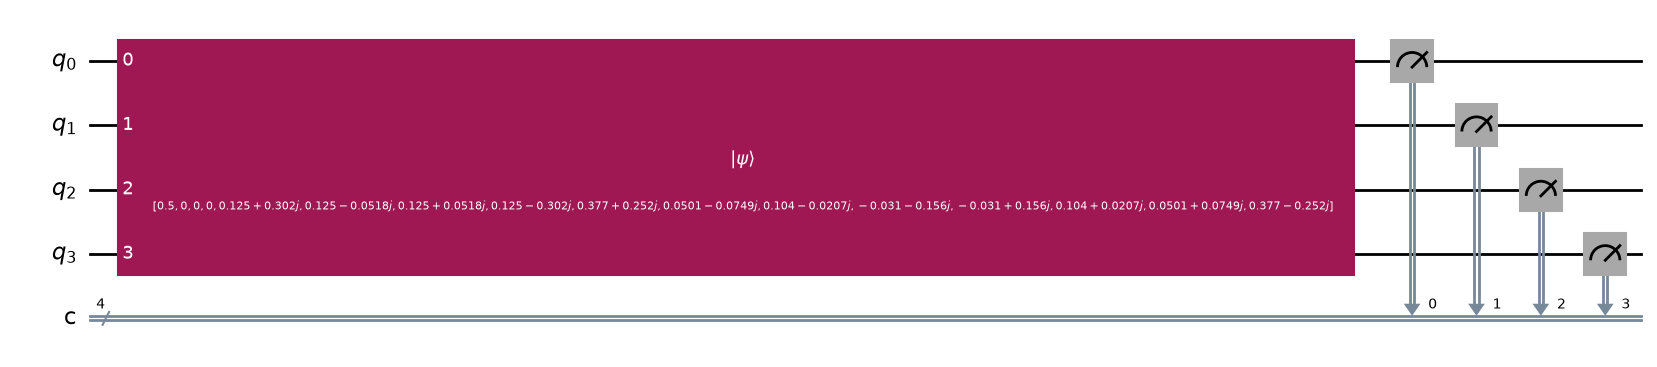

In [11]:
measurement_circuit = QuantumCircuit(
    num_qubits,
    num_qubits
)

measurement_circuit.initialize(
    frequency_state.data,
    range(num_qubits)
)

measurement_circuit.measure(
    range(num_qubits),
    range(num_qubits)
)

measurement_circuit.draw("mpl")

In [12]:
from qiskit_aer import AerSimulator

simulator = AerSimulator()

result = simulator.run(
    measurement_circuit,
    shots=1000
).result()

counts = result.get_counts()

print(counts)

{'1111': 224, '0111': 99, '1100': 32, '1000': 224, '0000': 219, '1011': 23, '1001': 8, '1101': 10, '0100': 102, '0101': 20, '0110': 19, '1010': 10, '1110': 10}


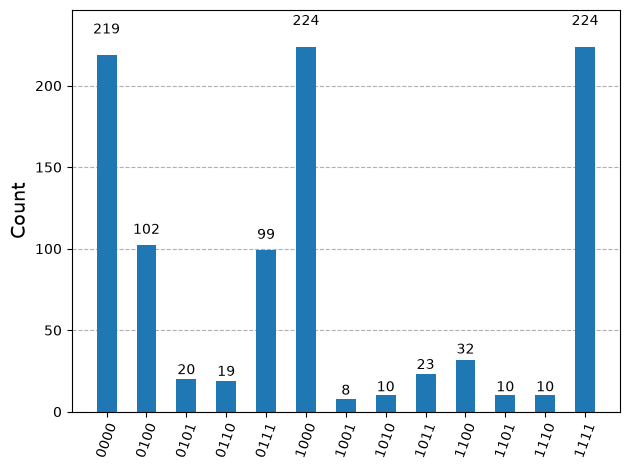

In [13]:
plot_histogram(counts)

In [14]:
sorted_results = sorted(
    counts.items(),
    key=lambda item: item[1],
    reverse=True
)

for state, count in sorted_results:
    decimal_value = int(state, 2)

    print(
        f"{state} -> {decimal_value} "
        f"({count} measurements)"
    )

1111 -> 15 (224 measurements)
1000 -> 8 (224 measurements)
0000 -> 0 (219 measurements)
0100 -> 4 (102 measurements)
0111 -> 7 (99 measurements)
1100 -> 12 (32 measurements)
1011 -> 11 (23 measurements)
0101 -> 5 (20 measurements)
0110 -> 6 (19 measurements)
1101 -> 13 (10 measurements)
1010 -> 10 (10 measurements)
1110 -> 14 (10 measurements)
1001 -> 9 (8 measurements)


In [15]:
r = 4

print(f"Recovered period: {r}")

Recovered period: 4


In [16]:
value = a ** (r // 2)

factor_1 = math.gcd(
    value - 1,
    N
)

factor_2 = math.gcd(
    value + 1,
    N
)

print(f"a^(r/2) = {value}")
print(f"First factor: {factor_1}")
print(f"Second factor: {factor_2}")

a^(r/2) = 4
First factor: 3
Second factor: 5


In [17]:
print(
    f"{factor_1} × {factor_2} "
    f"= {factor_1 * factor_2}"
)

print(
    f"Original number = {N}"
)

3 × 5 = 15
Original number = 15
